In [1]:
import pandas as pd
import numpy as np
from typing import Literal
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import r2_score, mean_absolute_error
import matplotlib.pyplot as plt
from scipy.stats import BootstrapMethod
from scipy.stats import bootstrap

In [2]:
df = pd.read_csv("../generated_data/big_five_evaluation_results_cleaned.csv")
df

,Gender,Enthusiasm,Assertiveness,Compassion,Politeness,Industriousness,Orderliness,Volatility,Withdrawal,Intellect,...,Openness_2,Openness_3_R,Openness_4_R,Intellect_1,Intellect_2_R,Intellect_3,Intellect_4_R,llm,persona,thinking
0,male,2.31,3.65,3.33,3.39,3.76,4.75,3.14,2.97,3.92,...,5,2,1,5,1.0,4,1,deepseek-v4-pro,description,enabled
1,male,2.86,2.94,3.28,3.29,2.91,3.74,3.28,3.17,3.70,...,2,4,5,5,1.0,5,1,deepseek-v4-pro,description,enabled
2,male,3.78,2.45,4.12,2.89,2.06,3.49,2.64,3.08,3.62,...,2,5,4,5,1.0,4,1,deepseek-v4-pro,description,enabled
3,male,2.86,2.64,4.16,3.49,2.53,2.99,2.44,3.11,3.09,...,5,1,1,3,2.0,2,2,deepseek-v4-pro,description,enabled
4,male,3.53,4.20,4.14,2.00,3.17,3.36,3.07,3.44,3.50,...,5,1,1,5,1.0,4,1,deepseek-v4-pro,description,enabled
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3595,female,3.69,2.86,3.54,3.16,2.69,2.52,2.90,2.54,3.88,...,5,1,1,5,3.0,5,1,deepseek-v4-flash,no_persona,disabled
3596,female,3.31,2.18,3.66,3.07,2.82,2.84,2.93,2.63,2.46,...,5,5,1,5,3.0,5,5,deepseek-v4-flash,no_persona,disabled
3597,female,2.38,4.42,3.16,2.43,2.20,1.27,2.29,2.41,3.92,...,5,1,3,5,5.0,5,3,deepseek-v4-flash,no_persona,disabled
3598,female,3.89,3.72,2.98,1.65,2.31,2.63,3.02,4.26,2.21,...,5,4,4,5,3.0,5,2,deepseek-v4-flash,no_persona,disabled


In [11]:
df.loc[2454, "Enthusiasm_4_R"]

'"\n\nThen the user prompt continues with: "You will be provided with a phrase describing people\'s behaviors. \nDescribe yourself as you generally are now, not as you wish to be in the future.\nDescribe yourself as you honestly see yourself, in relation to other people you know of the same sex as you are.\n\nRate the following statement on a scale from 1 to 5, where:\n1 - Very Inaccurate\n2 - Moderately Inaccurate\n3 - Neither Accurate, Nor Inaccurate\n4 - Moderately Accurate\n5 - Very Accurate\n\nYour entire response must consist of exactly one digit: 1, 2, 3, 4, or 5.\n-------------------------------------\nStatement:\nam not a very enthusiastic person"\n\nSo it seems like the "phrase describing people\'s behaviors" might be the statement itself, or maybe it\'s missing. Possibly, the task is to simulate a person with a particular trait, and the trait is given by the phrase? But the phrase is "am not a very enthusiastic person", which is a self-description. Maybe the simulation is: y

In [4]:
subfacette_item_cols = [col for col in df.columns if "_" in col and col not in ["Openness_Intellect", "experiment_group"]]

for item in subfacette_item_cols:
    df[item] = pd.to_numeric(df[item], errors="coerce")
    invalid_mask = ~df[item].isin([1, 2, 3, 4, 5])

    if invalid_mask.any():
        print(df.loc[invalid_mask, ["llm", "persona", "thinking", item]])
        print("--------------------")

    df = df.loc[~invalid_mask].copy()
    df[item] = df[item].astype("Int64")
df = df.dropna(axis=0).copy()

                   llm      persona thinking  Volatility_2_R
485  deepseek-v4-flash  description  enabled             NaN
--------------------
                   llm      persona thinking  Compassion_3_R
105    deepseek-v4-pro  description  enabled             NaN
580  deepseek-v4-flash  description  enabled             NaN
--------------------
                  llm     persona  thinking  Politeness_1_R
3013  deepseek-v4-pro  no_persona  disabled               6
--------------------
                    llm      persona thinking  Politeness_3
1598  deepseek-v4-flash  raw_persona  enabled           NaN
--------------------
                  llm     persona thinking  Enthusiasm_4_R
2454  deepseek-v4-pro  no_persona  enabled             NaN
--------------------
                 llm      persona  thinking  Assertiveness_4
736  deepseek-v4-pro  description  disabled              NaN
--------------------
                  llm      persona  thinking  Openness_1
1303  deepseek-v4-pro  raw_perso

In [5]:
# invert reverse coded items
reverse_cols = [col for col in df.columns if col.endswith("_R")]
df[reverse_cols] = 6 - df[reverse_cols]
df

,Gender,Enthusiasm,Assertiveness,Compassion,Politeness,Industriousness,Orderliness,Volatility,Withdrawal,Intellect,...,Openness_2,Openness_3_R,Openness_4_R,Intellect_1,Intellect_2_R,Intellect_3,Intellect_4_R,llm,persona,thinking
0,male,2.31,3.65,3.33,3.39,3.76,4.75,3.14,2.97,3.92,...,5,4,5,5,5,4,5,deepseek-v4-pro,description,enabled
1,male,2.86,2.94,3.28,3.29,2.91,3.74,3.28,3.17,3.70,...,2,2,1,5,5,5,5,deepseek-v4-pro,description,enabled
2,male,3.78,2.45,4.12,2.89,2.06,3.49,2.64,3.08,3.62,...,2,1,2,5,5,4,5,deepseek-v4-pro,description,enabled
3,male,2.86,2.64,4.16,3.49,2.53,2.99,2.44,3.11,3.09,...,5,5,5,3,4,2,4,deepseek-v4-pro,description,enabled
4,male,3.53,4.20,4.14,2.00,3.17,3.36,3.07,3.44,3.50,...,5,5,5,5,5,4,5,deepseek-v4-pro,description,enabled
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3595,female,3.69,2.86,3.54,3.16,2.69,2.52,2.90,2.54,3.88,...,5,5,5,5,3,5,5,deepseek-v4-flash,no_persona,disabled
3596,female,3.31,2.18,3.66,3.07,2.82,2.84,2.93,2.63,2.46,...,5,1,5,5,3,5,1,deepseek-v4-flash,no_persona,disabled
3597,female,2.38,4.42,3.16,2.43,2.20,1.27,2.29,2.41,3.92,...,5,5,3,5,1,5,3,deepseek-v4-flash,no_persona,disabled
3598,female,3.89,3.72,2.98,1.65,2.31,2.63,3.02,4.26,2.21,...,5,2,2,5,3,5,4,deepseek-v4-flash,no_persona,disabled


In [6]:
def get_traits(type: Literal["Big_Five", "Subdomain"]):
    """Return Big Five traits or subdomains."""
    
    big_five = {
        "Extraversion": ["Enthusiasm", "Assertiveness"],
        "Agreeableness": ["Compassion", "Politeness"],
        "Conscientiousness": ["Industriousness", "Orderliness"],
        "Neuroticism": ["Volatility", "Withdrawal"],
        "Openness_Intellect": ["Intellect", "Openness"],
    }

    if type == "Big_Five":
        return big_five

    return [subfacet for subfacets in big_five.values() for subfacet in subfacets]

In [7]:
subdomains = get_traits("Subdomain")
for subdomain in subdomains:
    subfacete_items = [col for col in df.columns if col.startswith(f"{subdomain}_") and not col.endswith("_Intellect")]
    df[f"{subdomain}_evaluated"] = df[subfacete_items].mean(axis=1)

big_five = get_traits("Big_Five")
for trait, subfacets in big_five.items():
    subfacet_cols = [f"{subfacet}_evaluated" for subfacet in subfacets]
    df[f"{trait}_evaluated"] = df[subfacet_cols].mean(axis=1)
df

,Gender,Enthusiasm,Assertiveness,Compassion,Politeness,Industriousness,Orderliness,Volatility,Withdrawal,Intellect,...,Orderliness_evaluated,Volatility_evaluated,Withdrawal_evaluated,Intellect_evaluated,Openness_evaluated,Extraversion_evaluated,Agreeableness_evaluated,Conscientiousness_evaluated,Neuroticism_evaluated,Openness_Intellect_evaluated
0,male,2.31,3.65,3.33,3.39,3.76,4.75,3.14,2.97,3.92,...,5.0,2.5,2.0,4.75,4.75,2.875,3.25,5.0,2.25,4.75
1,male,2.86,2.94,3.28,3.29,2.91,3.74,3.28,3.17,3.70,...,4.75,3.0,2.5,5.0,2.5,2.125,4.125,3.75,2.75,3.75
2,male,3.78,2.45,4.12,2.89,2.06,3.49,2.64,3.08,3.62,...,4.25,1.75,1.75,4.75,2.25,3.125,4.875,2.75,1.75,3.5
3,male,2.86,2.64,4.16,3.49,2.53,2.99,2.44,3.11,3.09,...,2.0,1.25,4.25,3.25,5.0,1.625,5.0,2.125,2.75,4.125
4,male,3.53,4.20,4.14,2.00,3.17,3.36,3.07,3.44,3.50,...,3.5,4.5,3.5,4.75,5.0,4.875,3.625,2.625,4.0,4.875
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3595,female,3.69,2.86,3.54,3.16,2.69,2.52,2.90,2.54,3.88,...,4.25,4.0,2.75,4.5,5.0,3.375,3.5,3.125,3.375,4.75
3596,female,3.31,2.18,3.66,3.07,2.82,2.84,2.93,2.63,2.46,...,3.75,3.5,3.0,3.5,4.0,3.25,3.625,2.625,3.25,3.75
3597,female,2.38,4.42,3.16,2.43,2.20,1.27,2.29,2.41,3.92,...,3.75,3.5,2.75,3.5,4.5,3.5,3.375,3.125,3.125,4.0
3598,female,3.89,3.72,2.98,1.65,2.31,2.63,3.02,4.26,2.21,...,4.0,4.25,2.75,4.25,3.25,3.125,3.0,3.0,3.5,3.75


In [8]:
def aggregate_metrics(df, traits, n_resamples=10_000):
    """Aggregate evaluation metrics across traits for each condition, with bootstrapped CIs."""
    evaluation_results = []
    alpha_adj = 0.05 / 12  # Bonferroni over 12 conditions, 99.58% CI

    for (llm, persona, thinking), condition in df.groupby(["llm", "persona", "thinking"]):
        y = condition[traits].astype(float)
        y_pred = condition[[f"{t}_evaluated" for t in traits]].astype(float)

        def aggregate(idx):
            # same resampled participants for all subdomains
            y_b, y_pred_b = y.iloc[idx], y_pred.iloc[idx]
            r = pearsonr(y_b, y_pred_b).statistic
    
            return (
                r.mean(), 
                r2_score(y_b, y_pred_b),                        
                mean_absolute_error(y_b, y_pred_b)
            )

        r_mean, r_2_mean, MAE_mean = aggregate(np.arange(len(condition)))
        ci = bootstrap((np.arange(len(condition)),), aggregate, vectorized=False,
                       n_resamples=n_resamples, confidence_level=1 - alpha_adj,
                       random_state=42).confidence_interval

        evaluation_results.append({
            "llm": llm,
            "persona": persona,
            "thinking": thinking,
            "N": len(condition),
            "pearson_r_mean": r_mean,
            "pearson_r_ci_lower": ci.low[0],
            "pearson_r_ci_upper": ci.high[0],
            "R²_mean": r_2_mean,
            "R²_ci_lower": ci.low[1],
            "R²_ci_upper": ci.high[1],
            "MAE_mean": MAE_mean,
            "MAE_ci_lower": ci.low[2],
            "MAE_ci_upper": ci.high[2],
        })

    return pd.DataFrame(evaluation_results)

aggregated_metrics_df = aggregate_metrics(df, get_traits("Subdomain"))

In [9]:
aggregated_metrics_df.round(2)

,llm,persona,thinking,N,pearson_r_mean,pearson_r_ci_lower,pearson_r_ci_upper,R²_mean,R²_ci_lower,R²_ci_upper,MAE_mean,MAE_ci_lower,MAE_ci_upper
0,deepseek-v4-flash,description,disabled,300,0.31,0.27,0.36,-0.71,-0.92,-0.50,0.67,0.63,0.70
1,deepseek-v4-flash,description,enabled,298,0.80,0.78,0.82,-1.39,-1.68,-1.10,0.89,0.86,0.92
2,deepseek-v4-flash,no_persona,disabled,300,-0.00,-0.05,0.05,-1.55,-1.79,-1.30,0.84,0.81,0.87
3,deepseek-v4-flash,no_persona,enabled,300,0.02,-0.03,0.08,-1.63,-1.87,-1.38,0.87,0.83,0.90
4,deepseek-v4-flash,raw_persona,disabled,300,0.41,0.35,0.47,-0.10,-0.23,0.02,0.52,0.50,0.55
5,deepseek-v4-flash,raw_persona,enabled,298,0.93,0.92,0.94,0.35,0.28,0.43,0.45,0.44,0.46
6,deepseek-v4-pro,description,disabled,299,0.47,0.42,0.51,-0.15,-0.27,-0.03,0.54,0.51,0.57
7,deepseek-v4-pro,description,enabled,299,0.82,0.80,0.83,-1.19,-1.45,-0.92,0.85,0.82,0.88
8,deepseek-v4-pro,no_persona,disabled,298,0.02,-0.04,0.07,-1.49,-1.74,-1.24,0.82,0.78,0.86
9,deepseek-v4-pro,no_persona,enabled,299,-0.01,-0.06,0.03,-0.33,-0.42,-0.25,0.60,0.57,0.63


In [10]:
def get_metrics(traits, df):
    """Compute evaluation metrics for subdomains or Big Five."""

    evaluation_results = []
    df = df.copy()
    for (llm, persona, thinking), condition in df.groupby(["llm", "persona", "thinking"]):
        
        for trait in traits:

            # assigned values
            y = condition[trait]
            # predicted values by the LLM
            y_pred = condition[f"{trait}_evaluated"]
        
            res = pearsonr(y, y_pred)
            alpha_adj = 0.05 / (len(traits) * 12)  # Bonferroni correction for multiple comparisons (5/10 traits * 12 conditions)
            ci = res.confidence_interval(confidence_level=1 - alpha_adj, method=BootstrapMethod(n_resamples=10_000, random_state=42))  # 99.96% CI 
            r, lower, upper = res.statistic, ci.low, ci.high
            pearson_sign = lower > 0 or upper < 0  
            
            spearman_rho, spearman_p = spearmanr(y, y_pred)
            
            evaluation_results.append({
                "llm": llm,
                "persona": persona,
                "thinking": thinking,
                "trait": trait,
                "N": len(y),
                "pearson_r": r,
                "pearson_sign": pearson_sign,
                "pearson_ci_lower": lower,
                "pearson_ci_upper": upper,
                "spearman_rho": spearman_rho,
                "spearman_p": spearman_p,
                "R²": r2_score(y, y_pred),
                "MAE": mean_absolute_error(y, y_pred),
            })
    evaluation_df = pd.DataFrame(evaluation_results)
    evaluation_df["spearman_p_adjusted"] = (evaluation_df["spearman_p"] * len(evaluation_df)).clip(upper=1)

    return evaluation_df
    

In [12]:
subdomain_df

,llm,persona,thinking,trait,N,pearson_r,pearson_sign,pearson_ci_lower,pearson_ci_upper,spearman_rho,spearman_p,R²,MAE,spearman_p_adjusted
0,deepseek-v4-flash,description,disabled,Enthusiasm,300,0.464345,True,0.273644,0.602510,0.498978,2.718157e-20,-1.087485,0.781933,3.261789e-18
1,deepseek-v4-flash,description,disabled,Assertiveness,300,0.639620,True,0.514402,0.735573,0.638203,1.022101e-35,0.345787,0.413833,1.226522e-33
2,deepseek-v4-flash,description,disabled,Compassion,300,0.564805,True,0.388961,0.690825,0.522867,1.889152e-22,0.147483,0.443333,2.266982e-20
3,deepseek-v4-flash,description,disabled,Politeness,300,0.074653,False,-0.136246,0.290146,0.069289,2.314849e-01,-1.624729,0.811567,1.000000e+00
4,deepseek-v4-flash,description,disabled,Industriousness,300,-0.042674,False,-0.235335,0.130497,-0.082131,1.558950e-01,-3.570531,1.297300,1.000000e+00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,deepseek-v4-pro,raw_persona,enabled,Orderliness,299,0.957975,True,0.942414,0.969802,0.971884,1.371025e-188,0.579120,0.345452,1.645230e-186
116,deepseek-v4-pro,raw_persona,enabled,Volatility,299,0.946662,True,0.928908,0.961499,0.965314,2.940282e-175,0.695513,0.346488,3.528338e-173
117,deepseek-v4-pro,raw_persona,enabled,Withdrawal,299,0.956671,True,0.938082,0.970667,0.961372,1.915282e-168,0.567696,0.396656,2.298339e-166
118,deepseek-v4-pro,raw_persona,enabled,Intellect,299,0.916713,True,0.884425,0.941807,0.935942,1.183068e-136,0.199584,0.496522,1.419681e-134


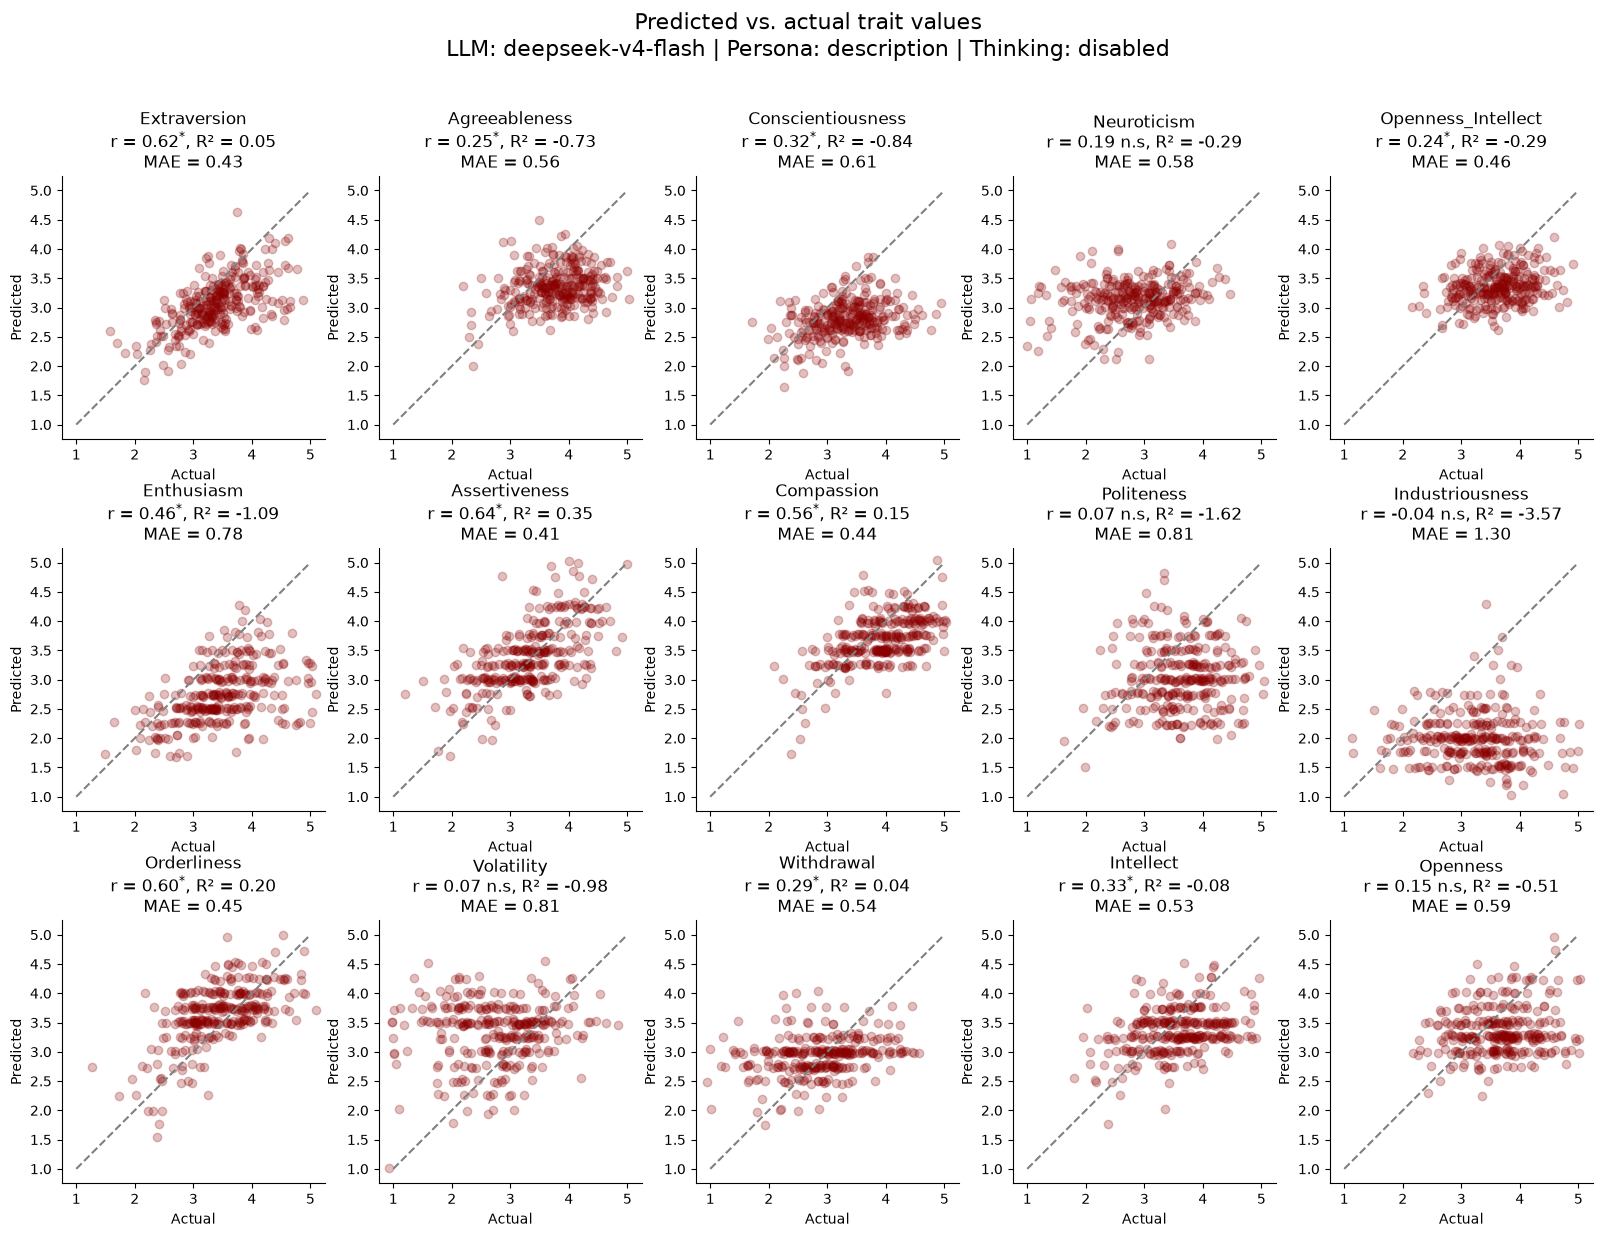

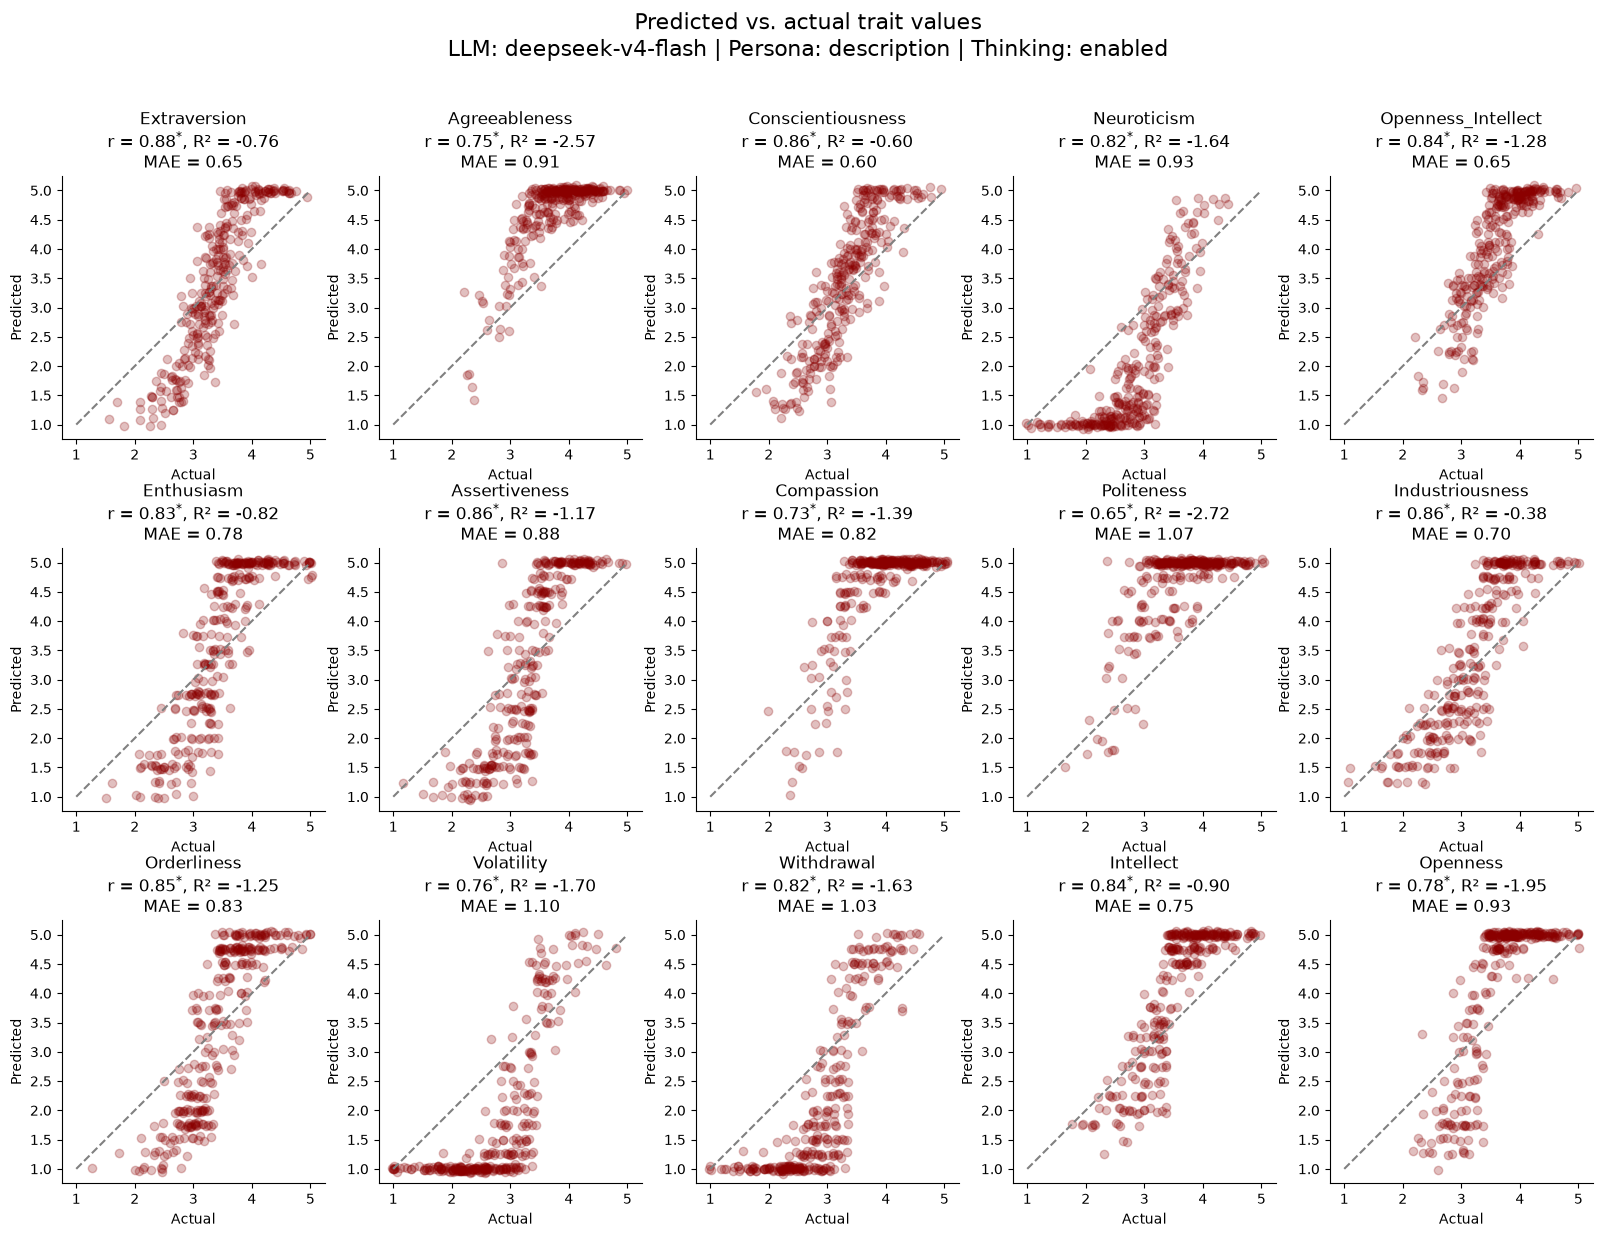

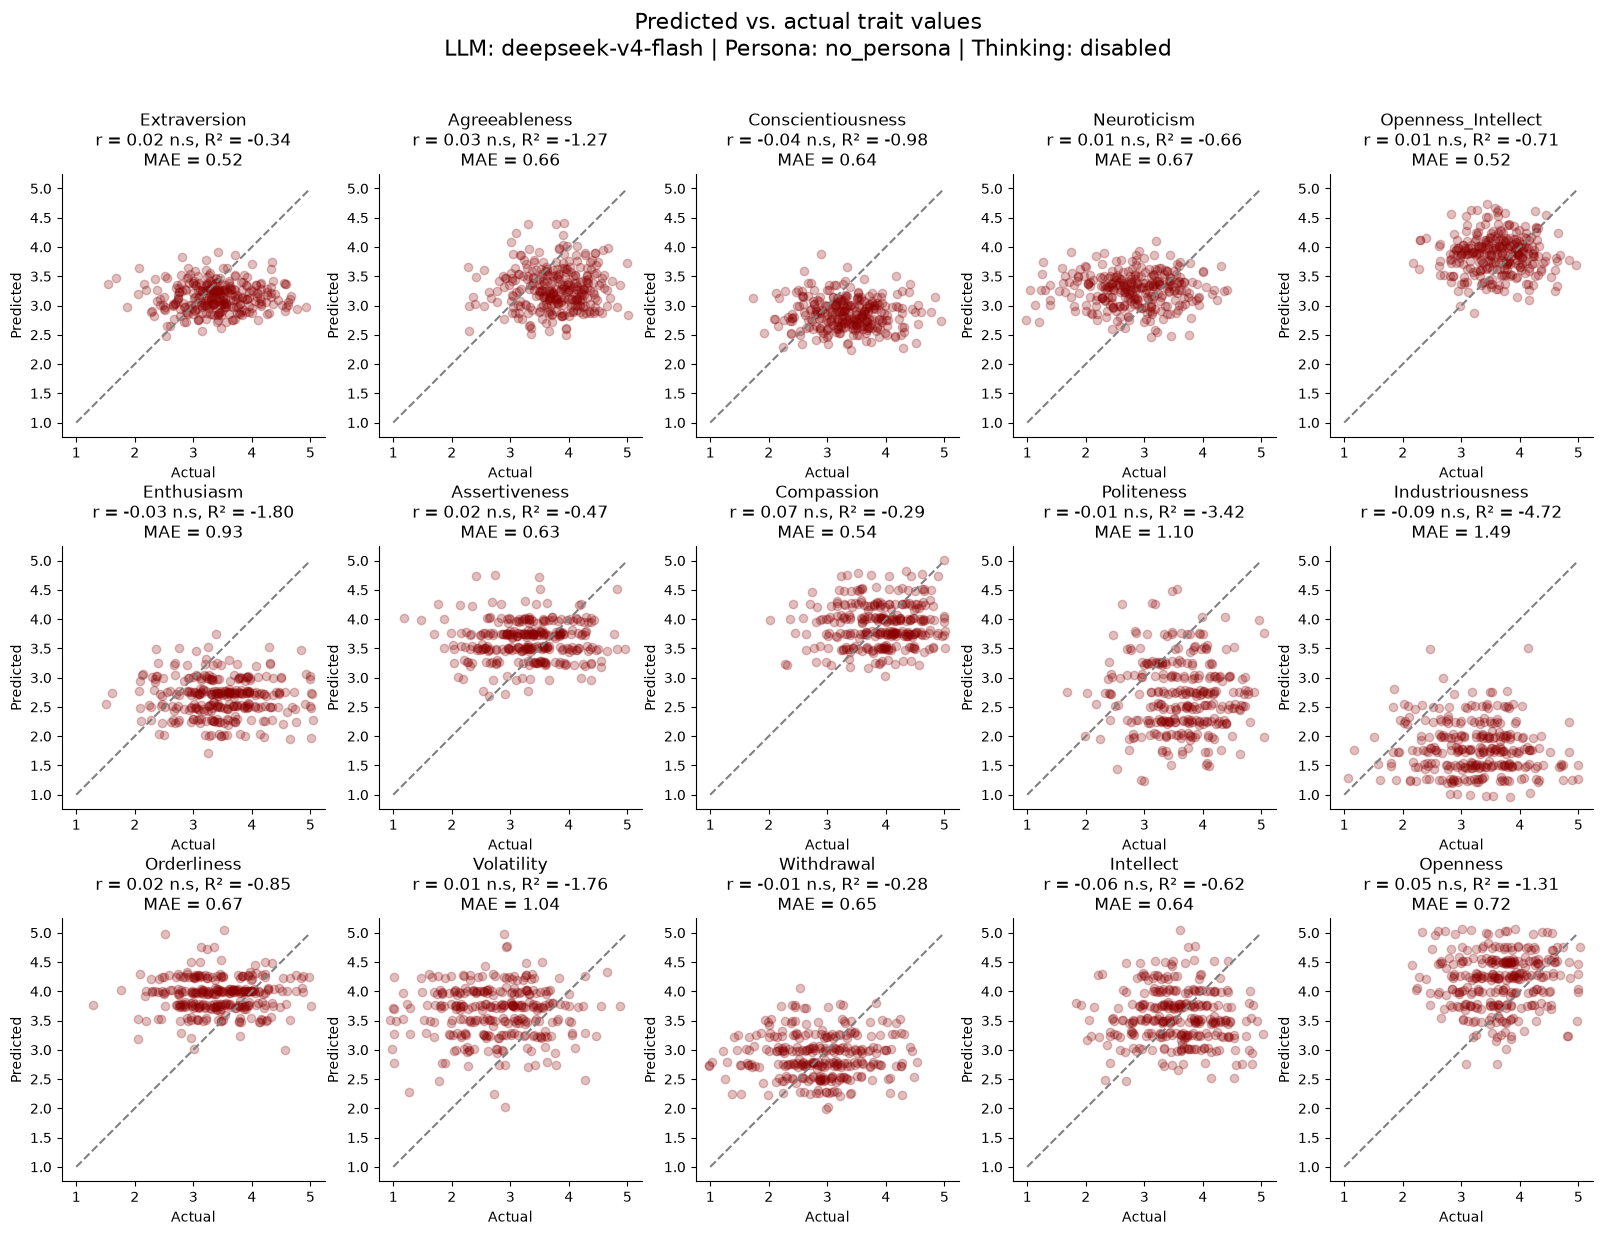

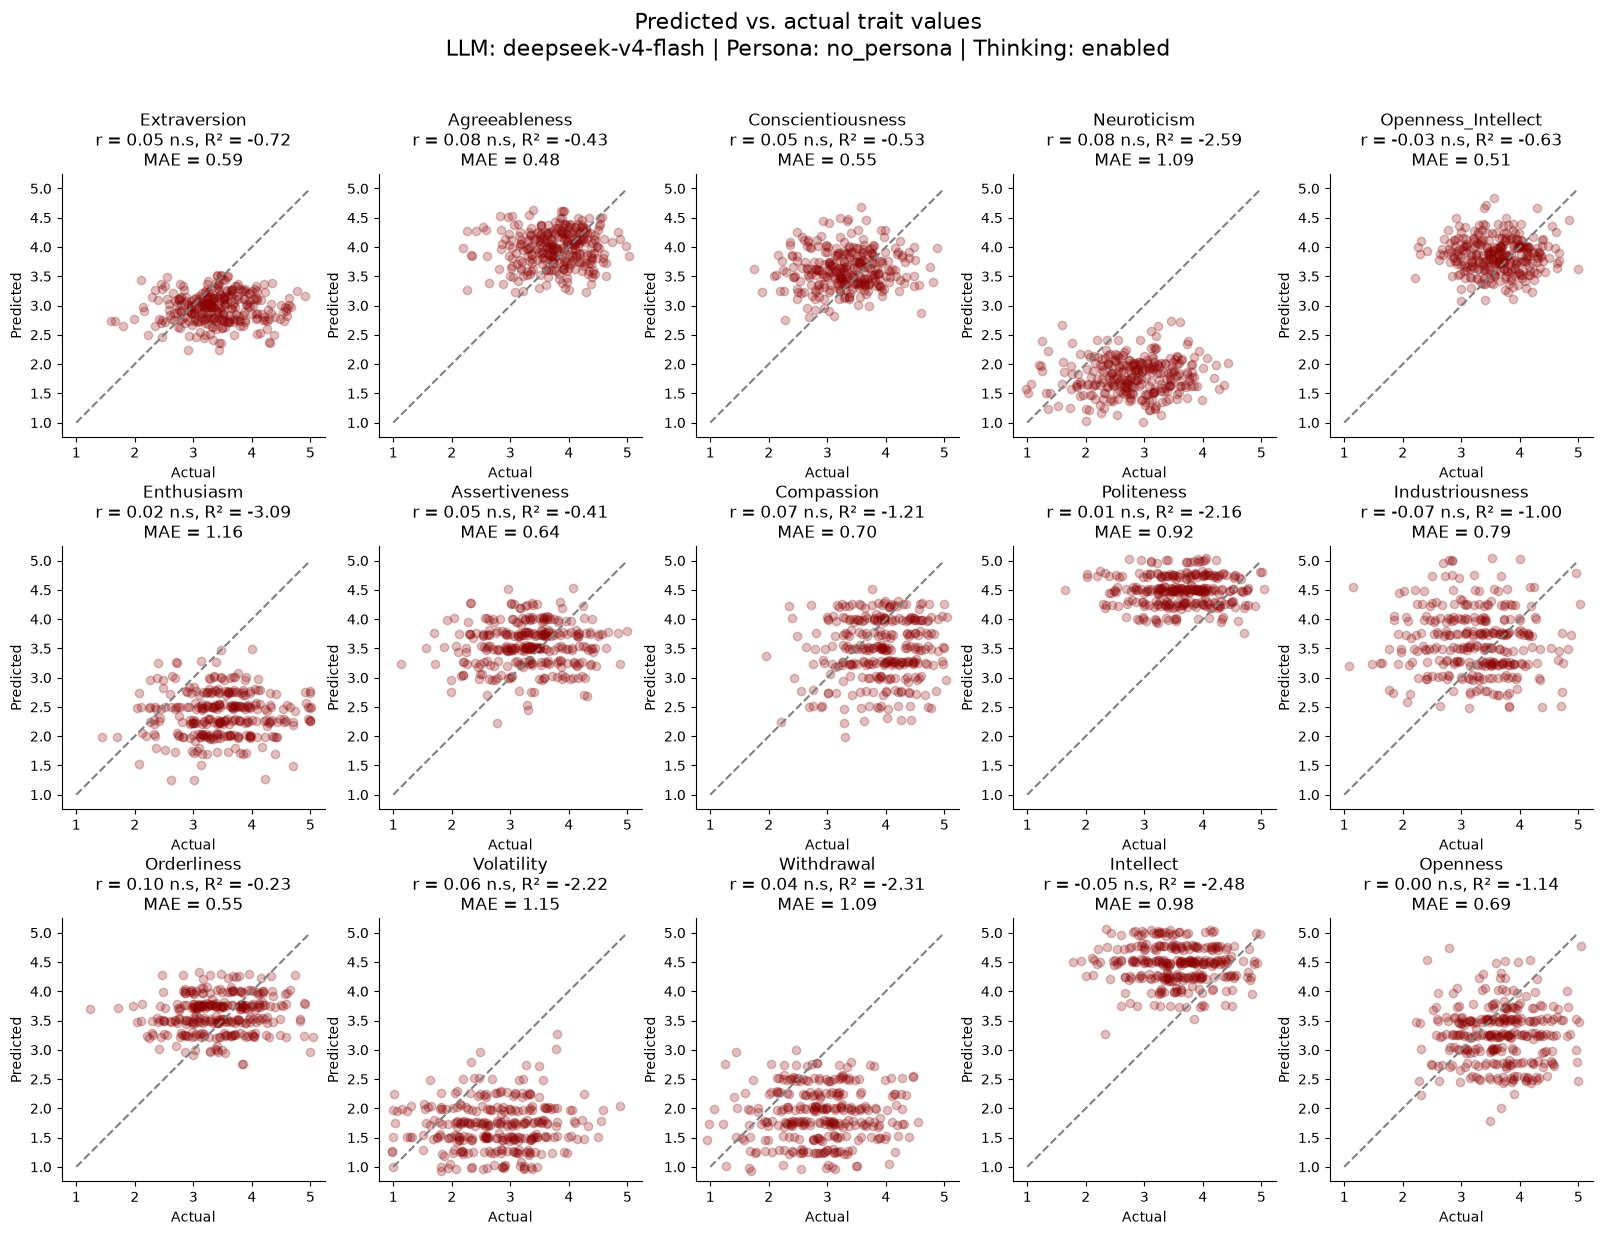

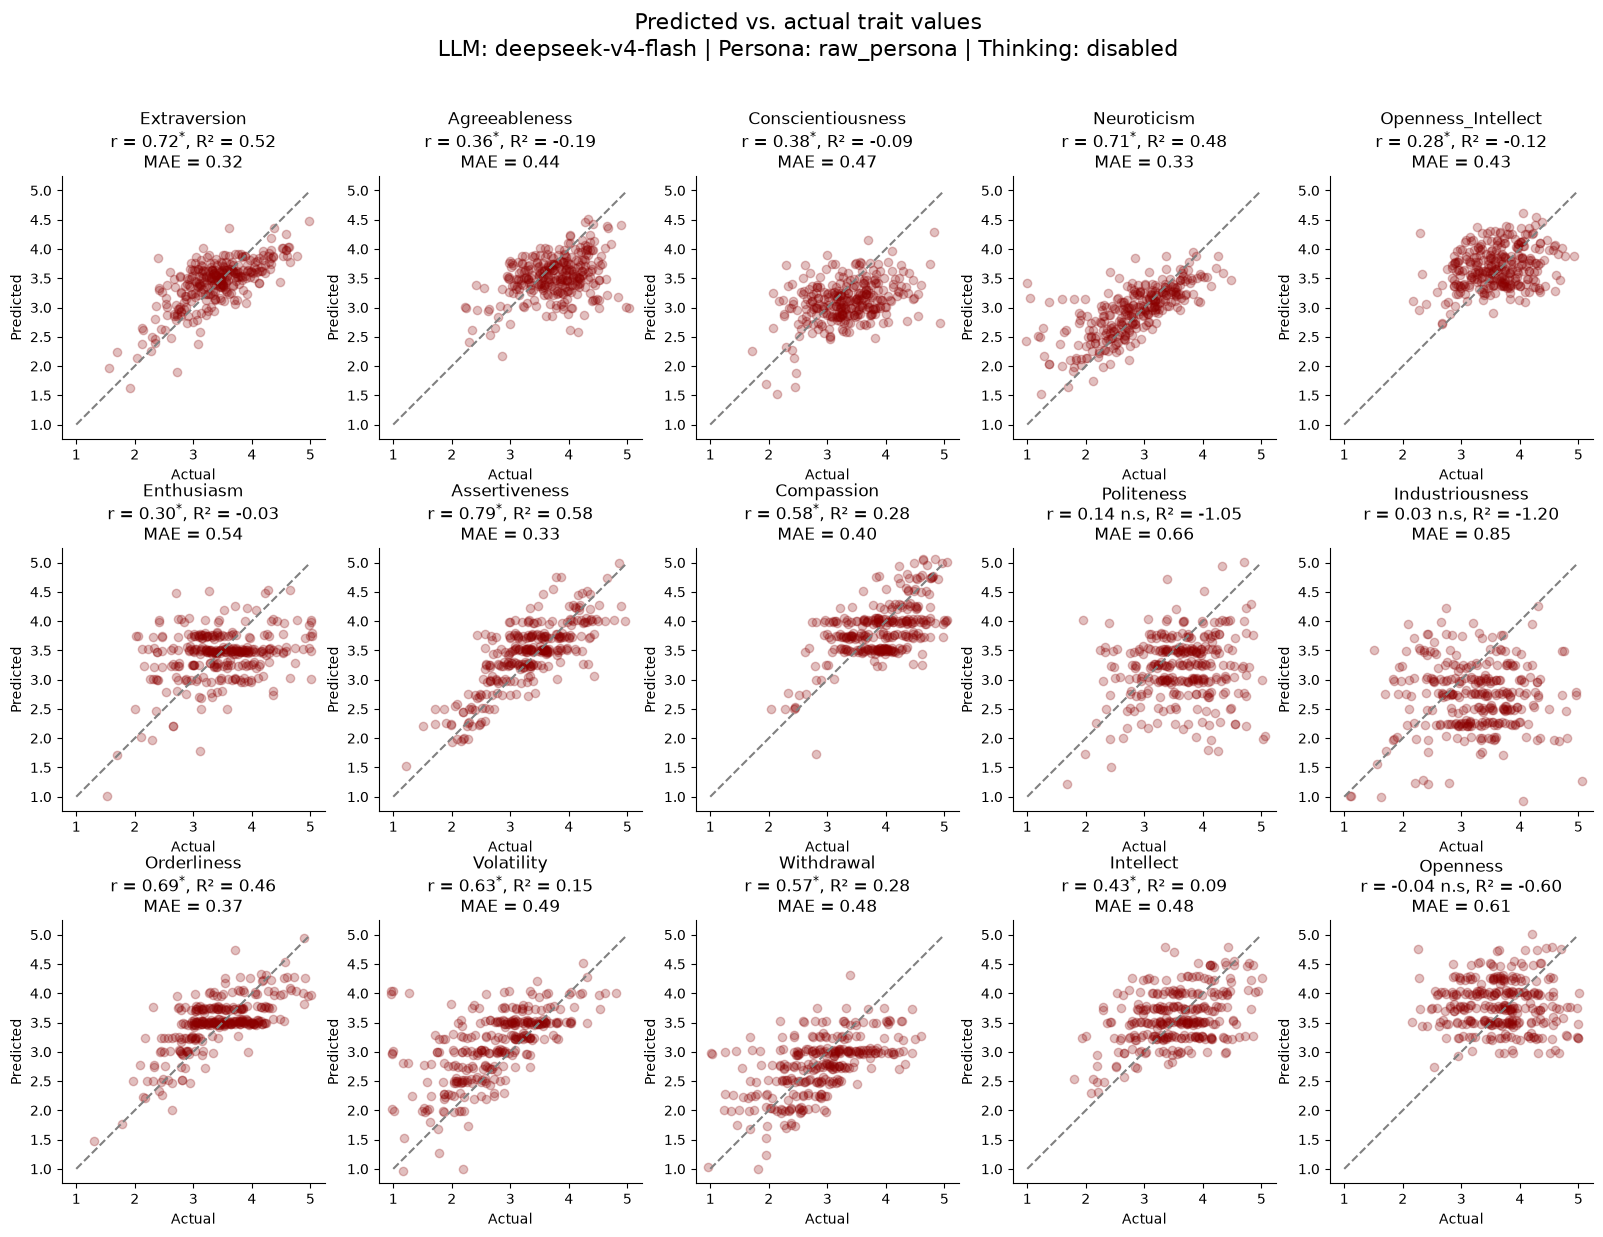

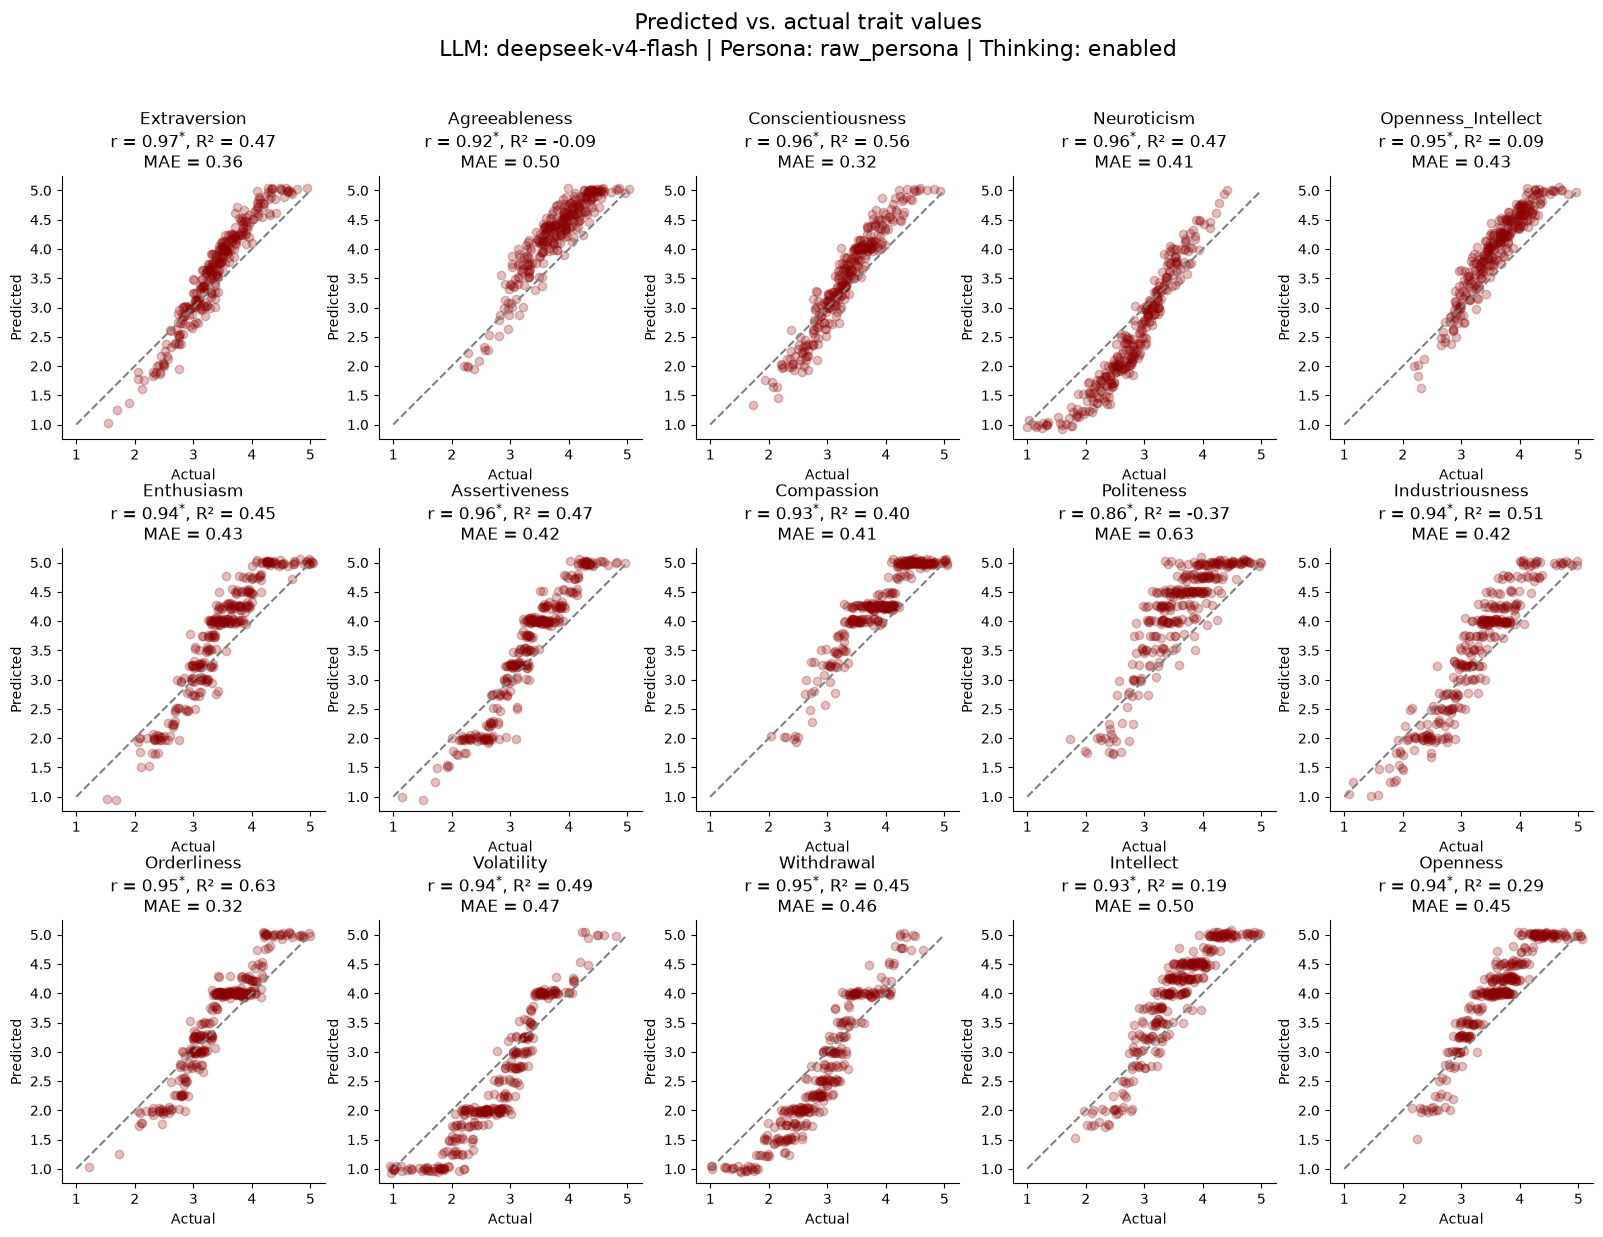

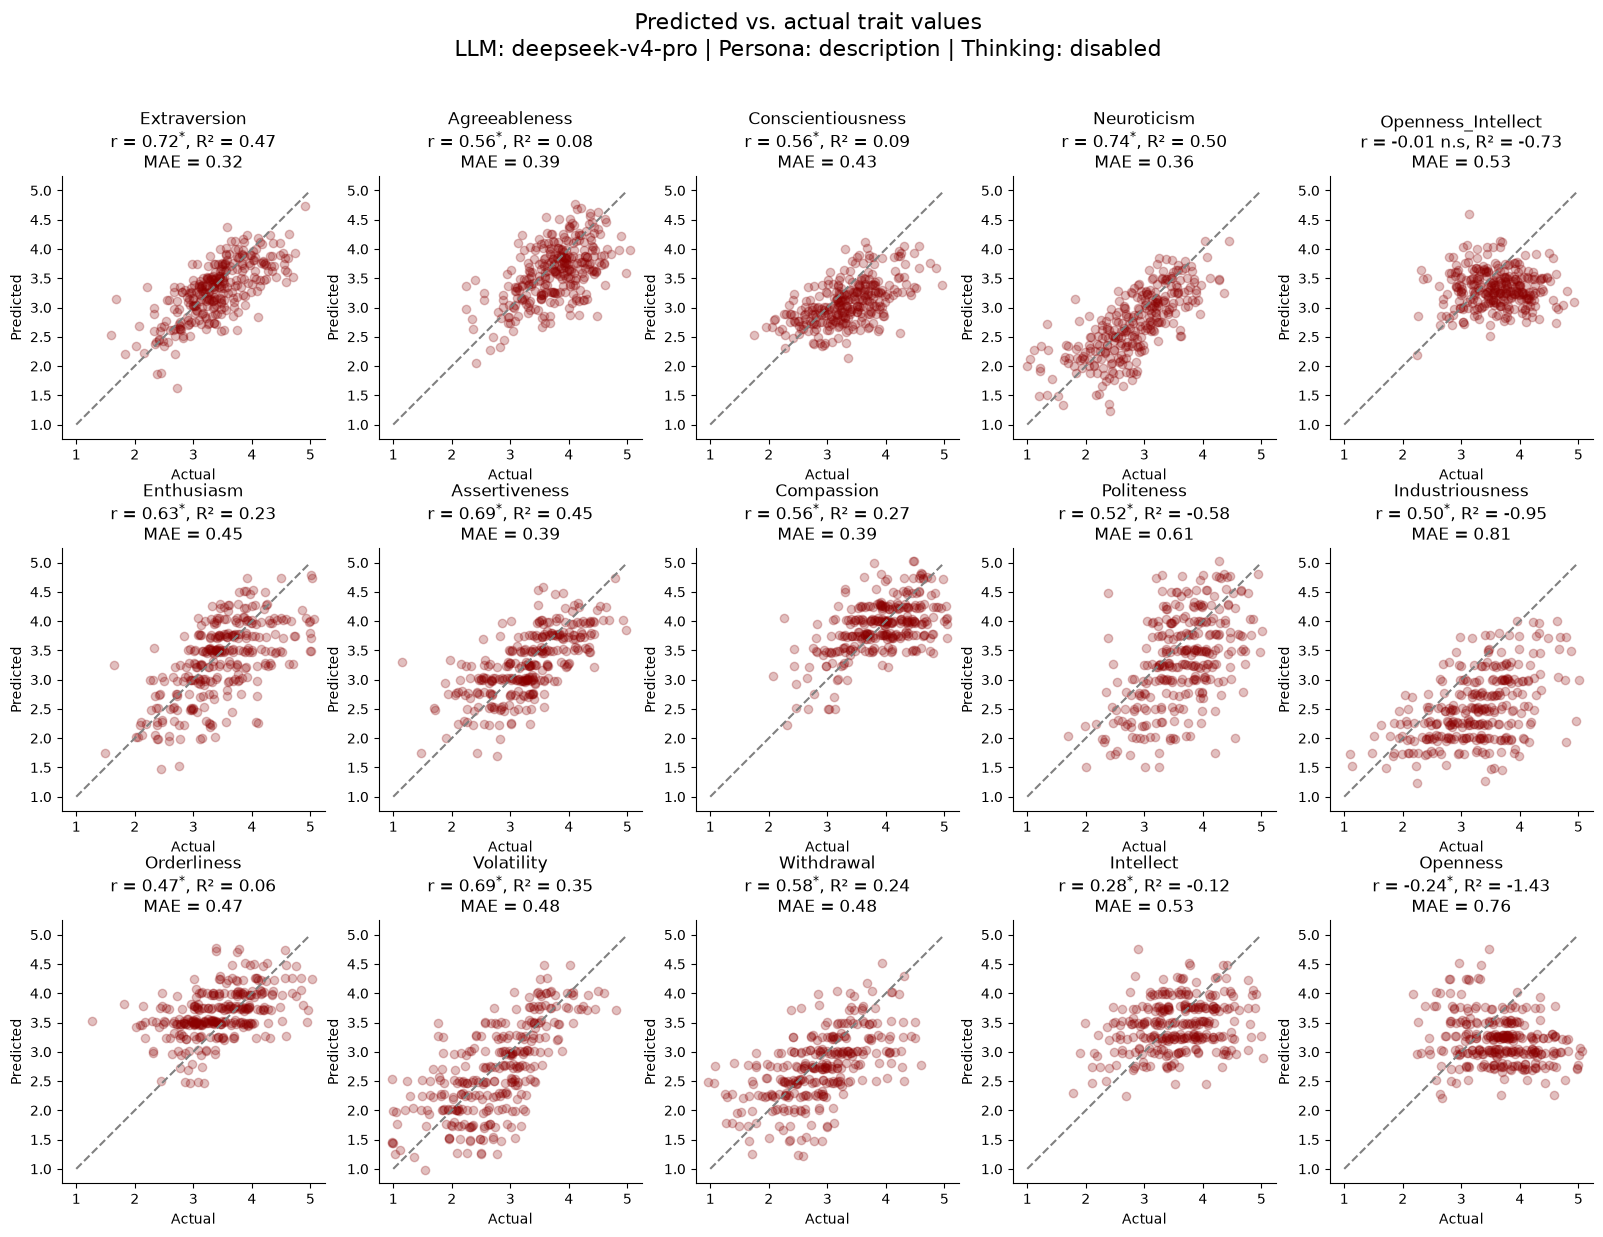

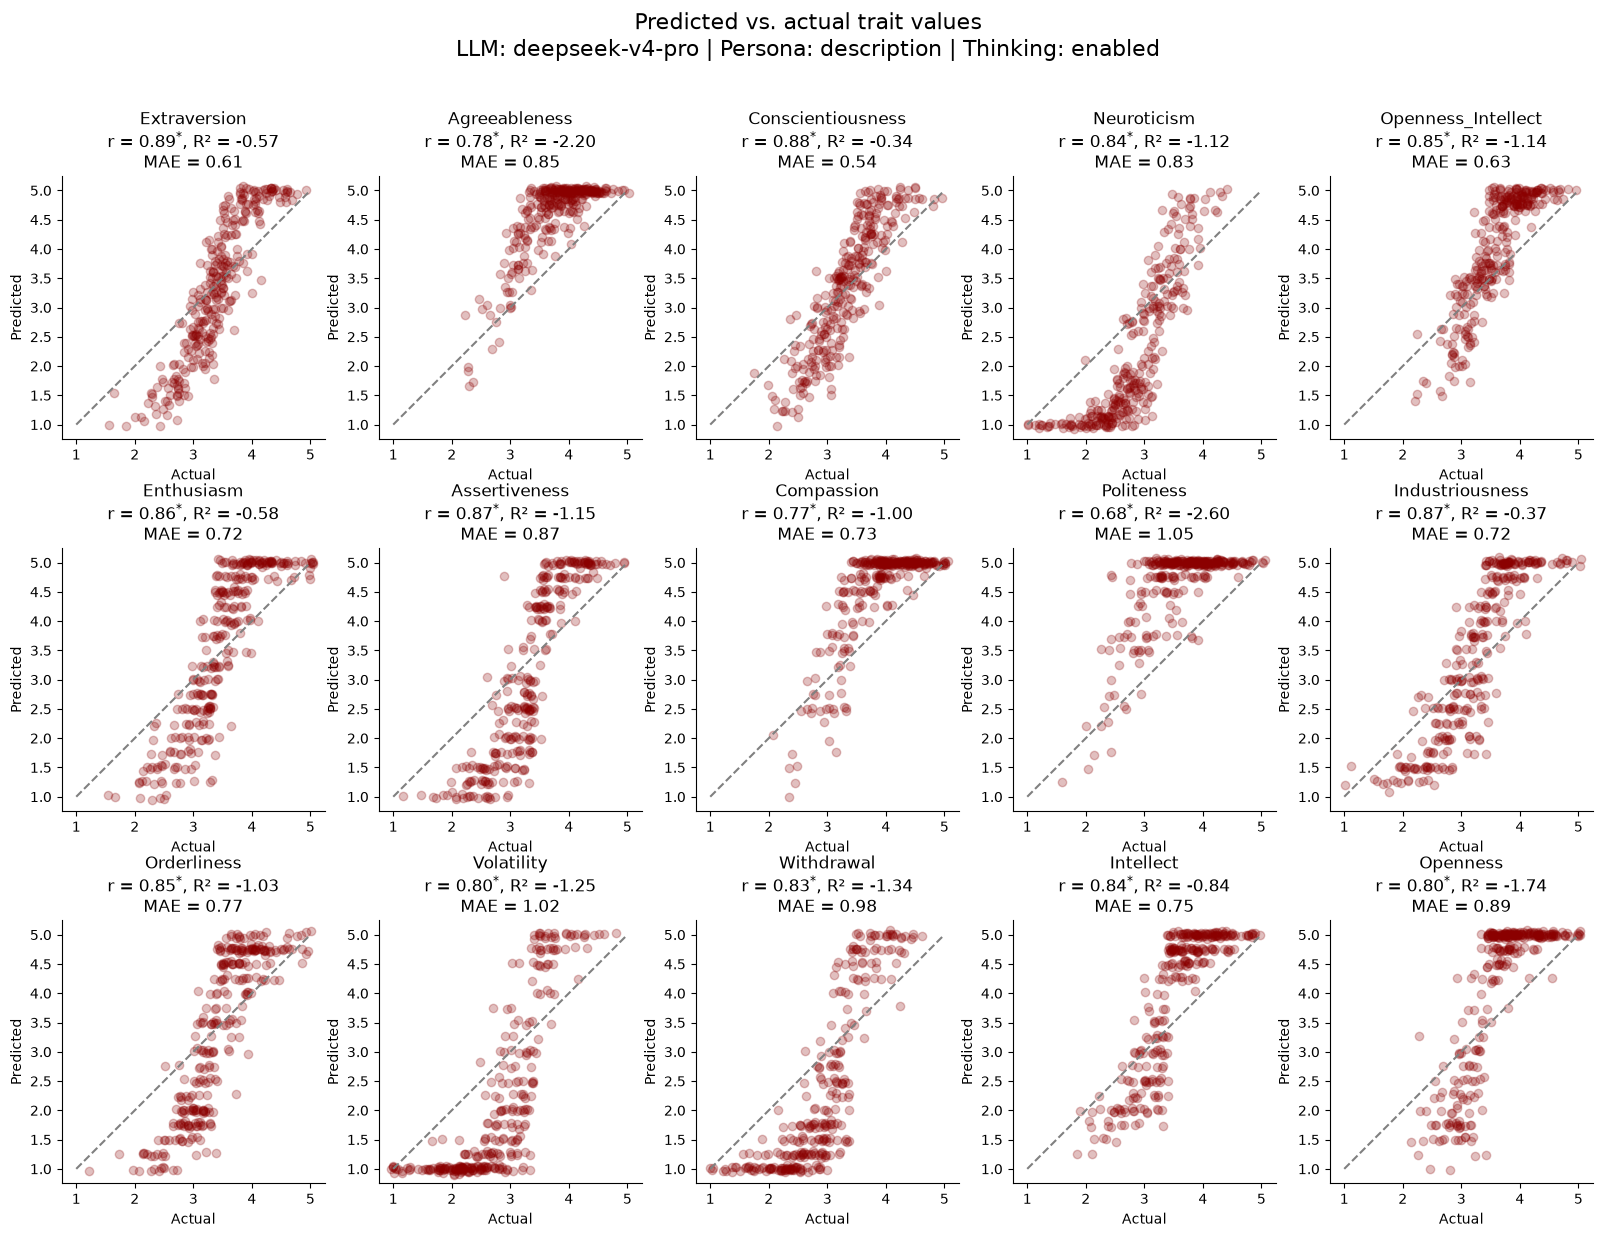

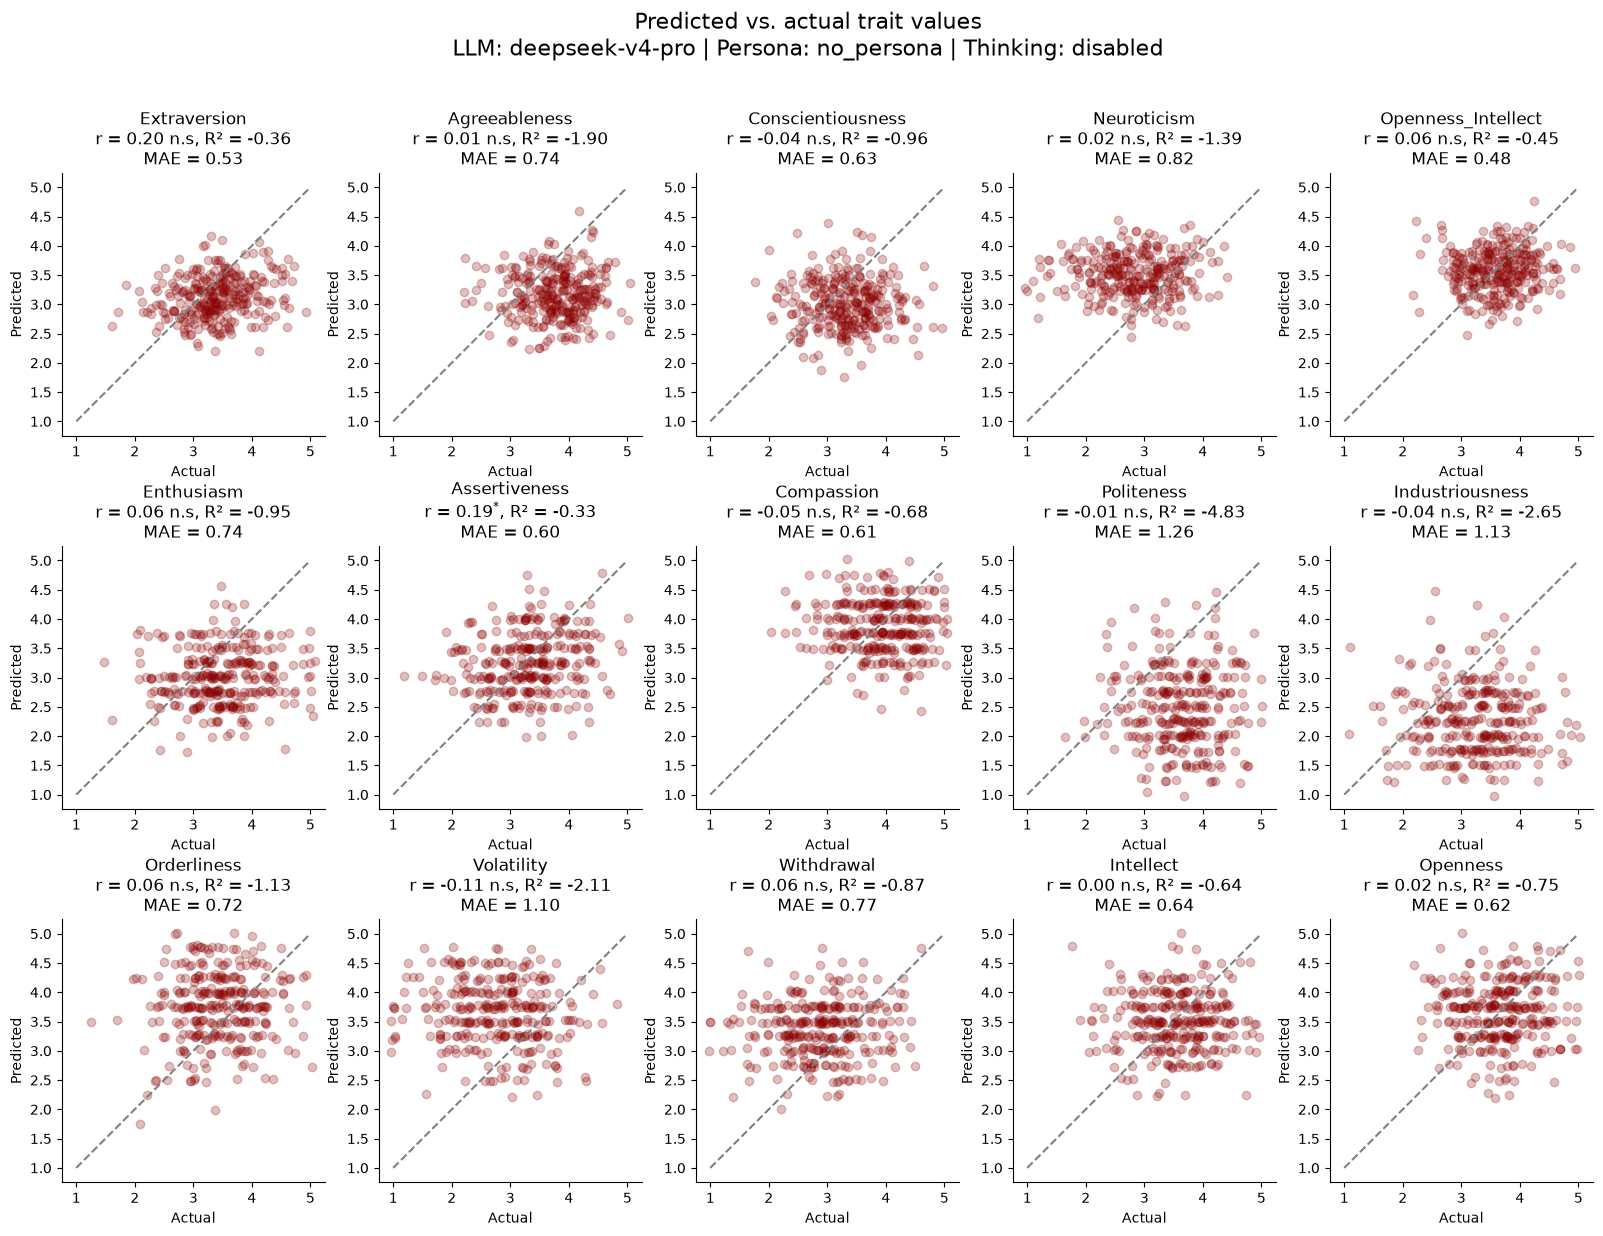

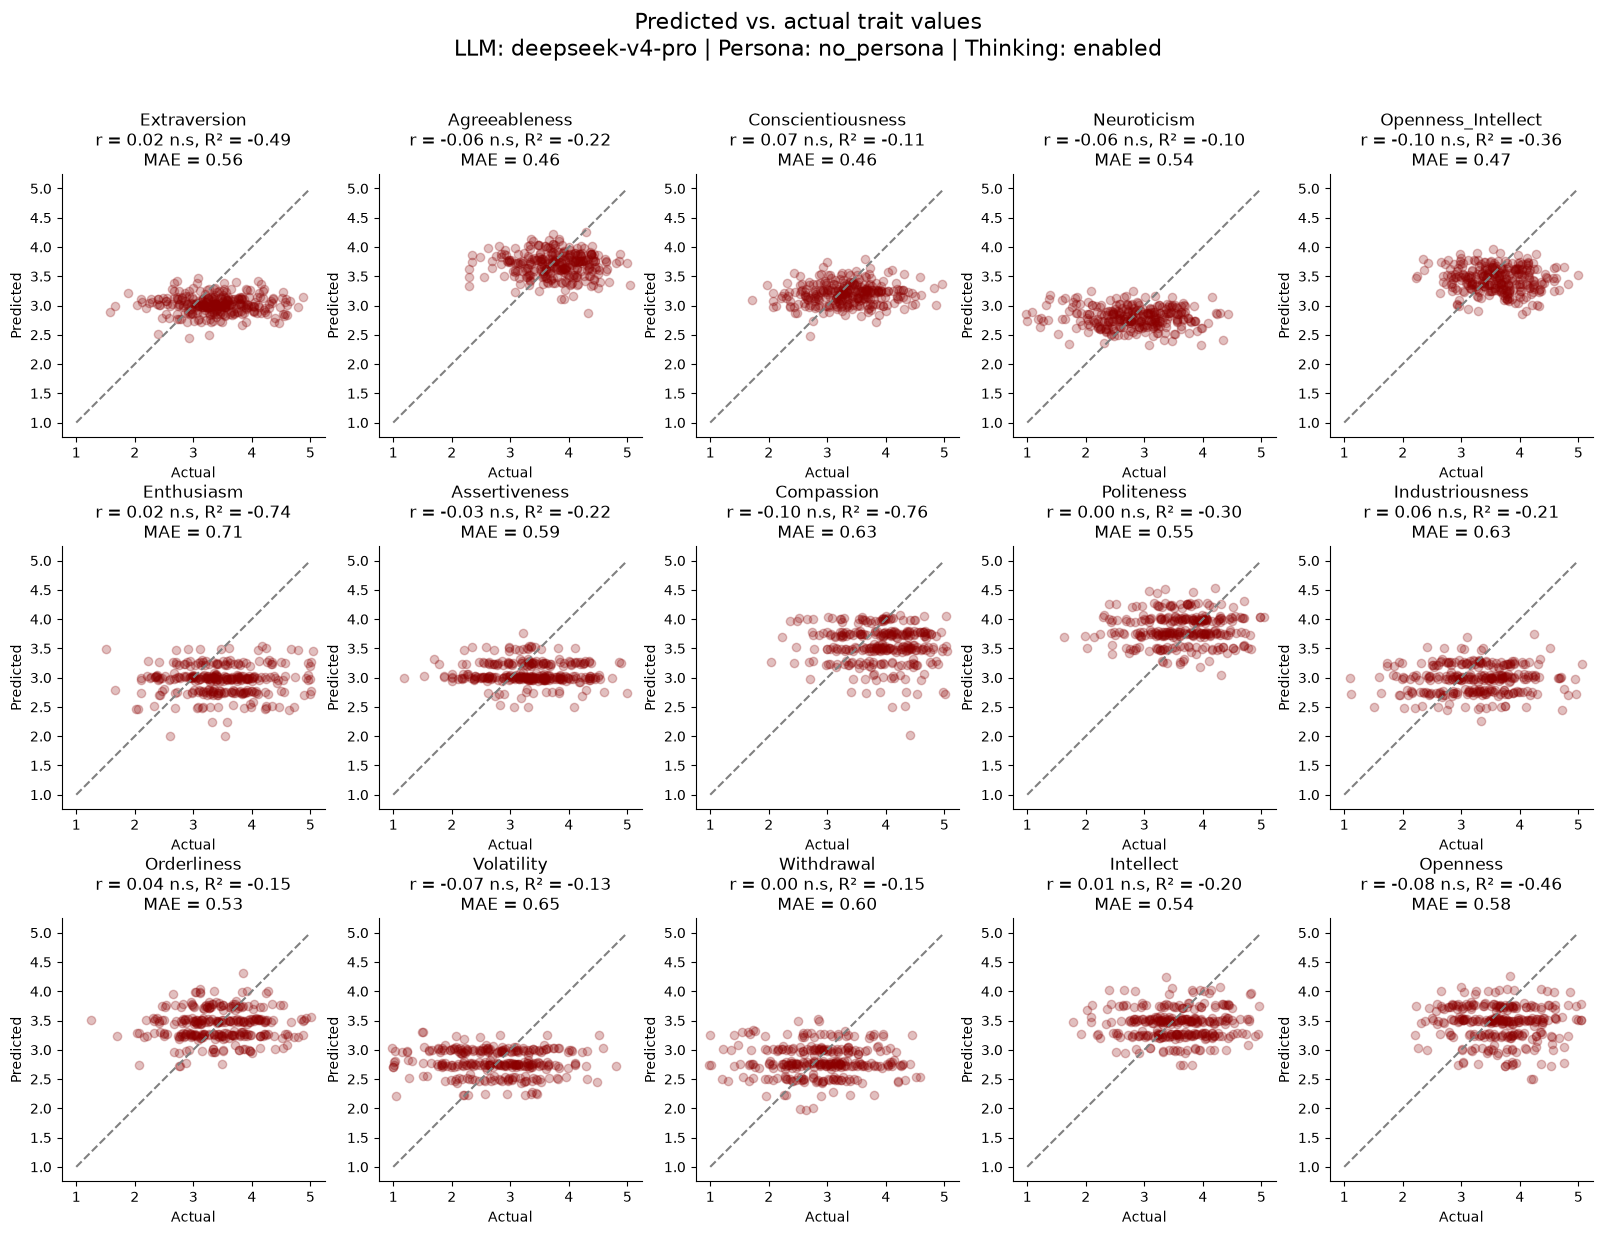

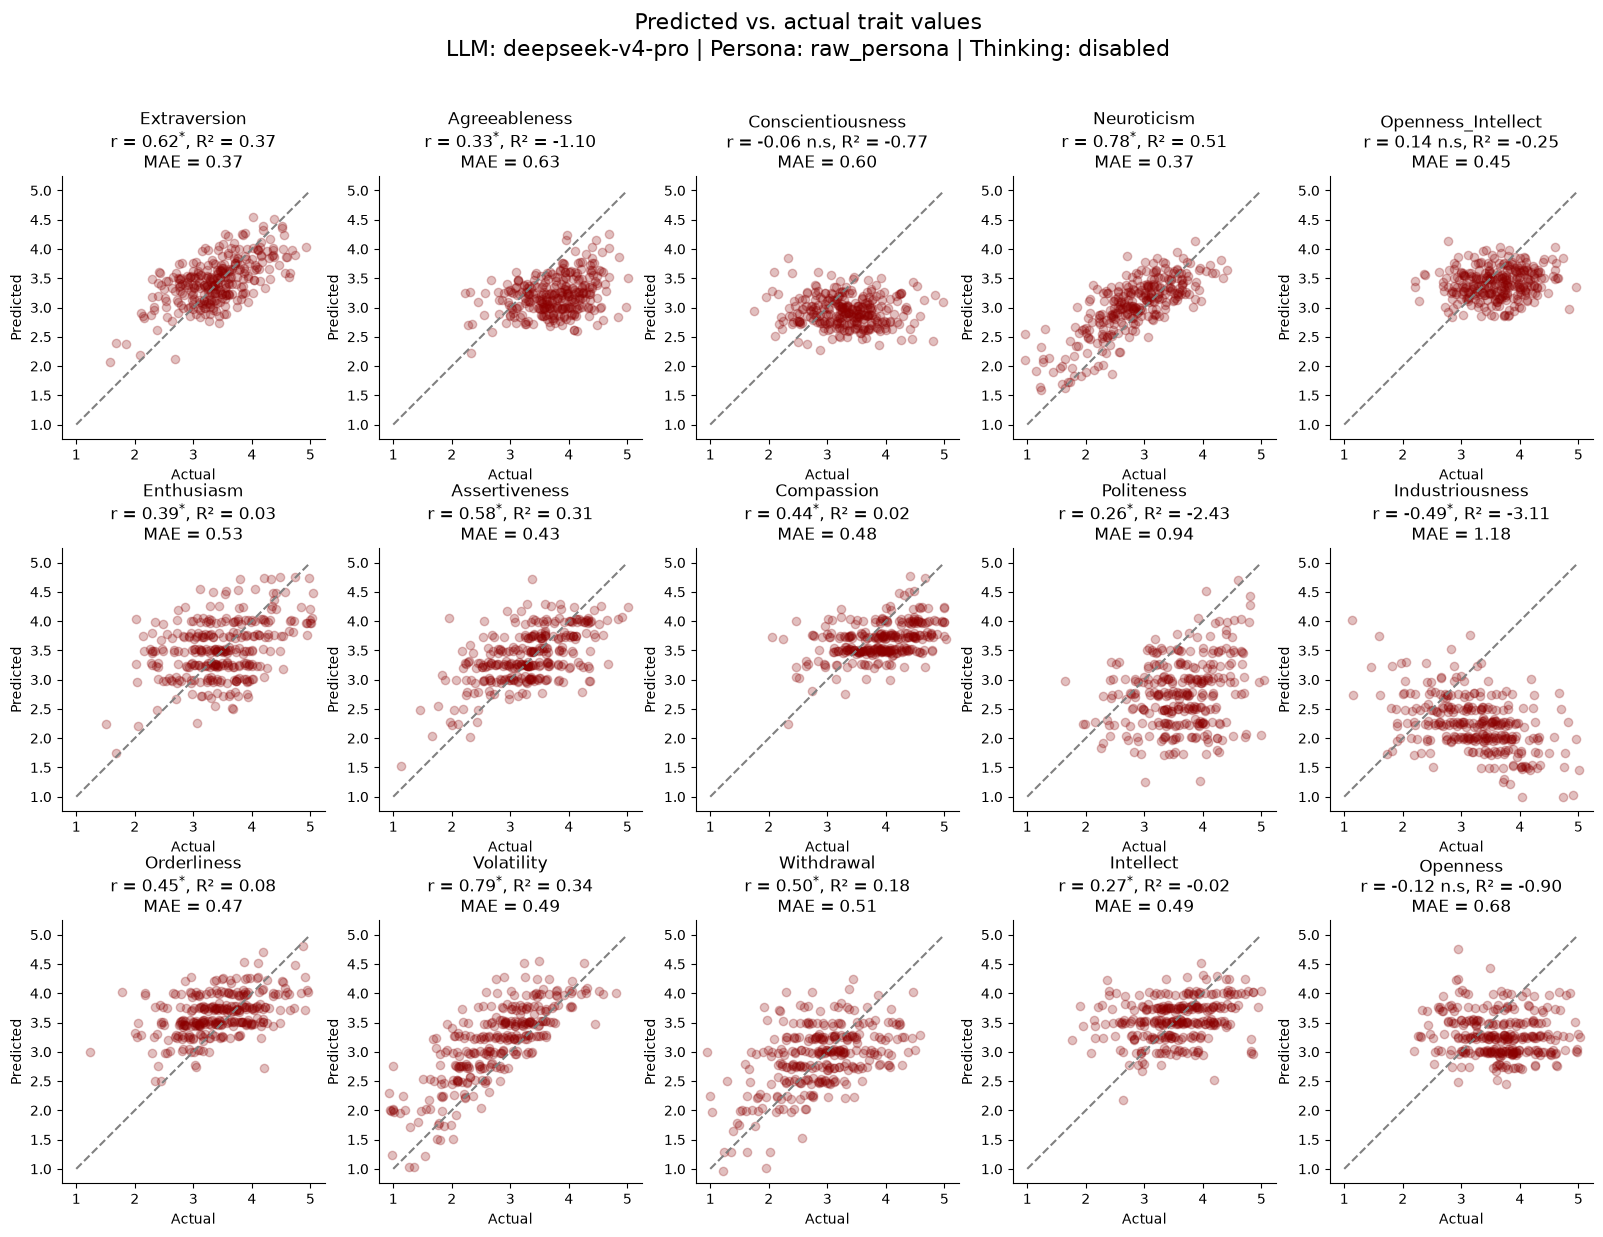

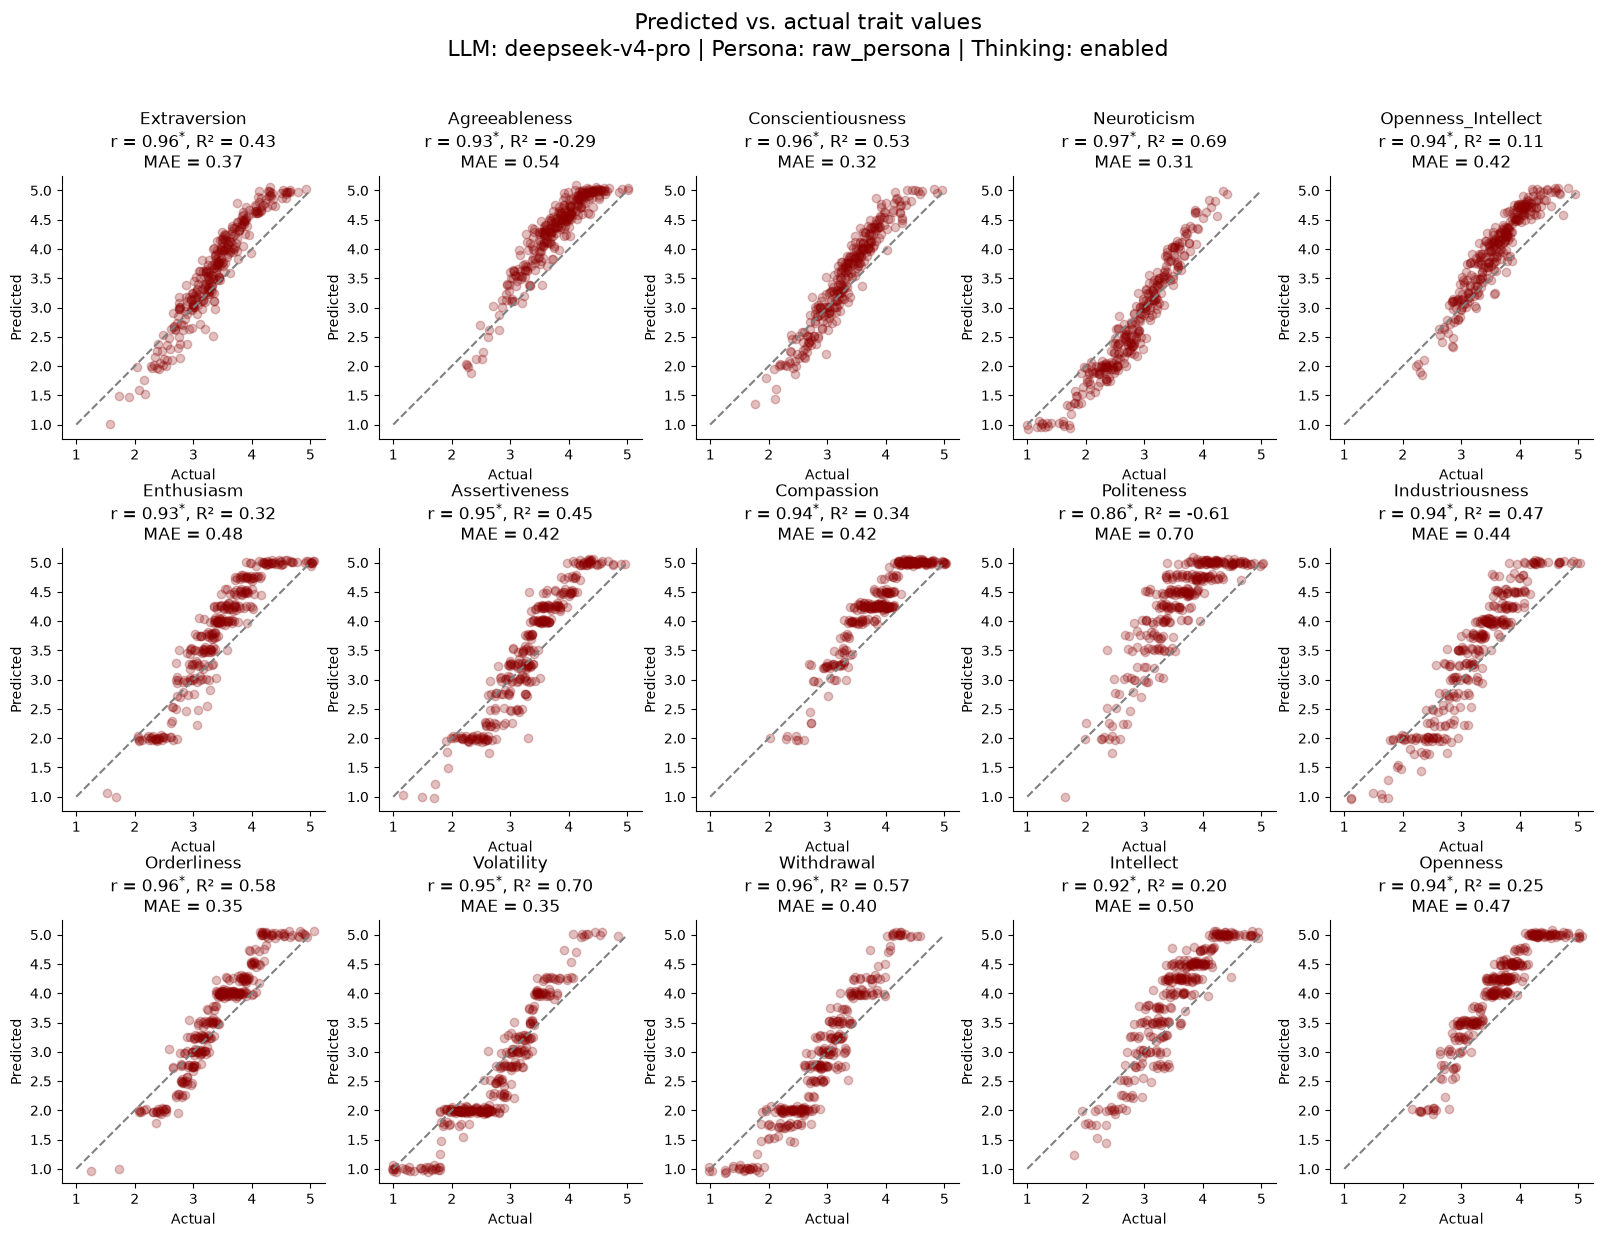

In [11]:
big_five = get_traits("Big_Five").keys()
subdomains = get_traits("Subdomain")

subdomain_df = get_metrics(subdomains, df)
big_five_df = get_metrics(big_five, df)

rng = np.random.default_rng(42)
jitter_sd = 0.03

def plot_trait(ax, condition, trait, metrics_df, llm, persona, thinking):
    x_jitter = rng.normal(0, jitter_sd, len(condition))
    y_jitter = rng.normal(0, jitter_sd, len(condition))

    # Point-level data
    actual = condition[trait]
    predicted = condition[f"{trait}_evaluated"]

    # Get metrics
    metrics = metrics_df[
        (metrics_df["llm"] == llm) &
        (metrics_df["persona"] == persona) &
        (metrics_df["thinking"] == thinking) &
        (metrics_df["trait"] == trait)
    ].iloc[0]

    # Scatter plot
    ax.scatter(
        actual + x_jitter,
        predicted + y_jitter,
        alpha=0.25,
        c="darkred",
    )

    # Perfect prediction line
    ax.plot(
        [1, 5],
        [1, 5],
        linestyle="--",
        color="gray",
    )

    # Metrics
    
    sign = "$^{*}$" if metrics["pearson_sign"] else " n.s"
    ax.set_title(
        f"{trait}\n"
        f"r = {metrics['pearson_r']:.2f}{sign}, "
        f"R² = {metrics['R²']:.2f}\n"
        f"MAE = {metrics['MAE']:.2f}"
    )

    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted")
    ax.set_xlim(.75, 5.25)
    ax.set_ylim(.75, 5.25)

    ax.set_aspect("equal", adjustable="box")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


for (llm, persona, thinking), condition in df.groupby(["llm", "persona", "thinking"]):

    n_cols = 5
    n_rows = 3

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(16, 4 * n_rows)
    )

    # Big Five domains
    for ax, trait in zip(axes[0], big_five):
        plot_trait(ax, condition, trait, big_five_df, llm, persona, thinking)

    # subdomains
    sub_axes = axes[1:].flatten()
    for ax, trait in zip(sub_axes, subdomains):
        plot_trait(ax, condition, trait, subdomain_df, llm, persona, thinking)

    # Remove unused axes
    for ax in axes[0][len(big_five):]:
        ax.remove()
    for ax in sub_axes[len(subdomains):]:
        ax.remove()

    fig.suptitle(
        f"Predicted vs. actual trait values\n"
        f"LLM: {llm} | Persona: {persona} | Thinking: {thinking}",
        fontsize=16,
        y=1.02
        )
    fig.tight_layout()
    # fig.savefig(f"plots/big_five_evaluation/big_five_evaluation_{llm}_{persona}_{thinking}.png", bbox_inches="tight")